# CARE wind-turbine SCADA: CatBoost + ridge logistic regression, correlation and blend weights

**Goal.** Test whether a strongly regularised linear model (logistic regression with an L2 / ridge penalty) adds to the
CatBoost baseline when there are only 44 anomaly events (A 11, B 6, C 27): how correlated the two models are, which blend
weight to use, and the final scores against the baseline rules (`notebooks/care_catboost_baseline.md`, section 8).

**Sections 1 to 7 are copied unchanged from `notebooks/care_catboost_baseline.ipynb`** (columns, timelines, the daily
deviation table, labels, features, folds and the evaluation engine), so the labels, features, folds and metrics are exactly
the baseline's. The daily deviation table and the folds are read from the baseline cache
(`dataset/wind_turbine_scada_fault/cache/catboost_baseline/`); the folds are recomputed and checked against the saved file.
New work starts at section 8. Outputs go to `dataset/wind_turbine_scada_fault/cache/catboost_ridge/`.

Target: k = 7, "day t is inside an anomaly window or one starts within 7 days". Headline metrics: ROC-AUC (pooled and within
turbine) and event recall at at most 1 false alarm per turbine-month on the test turbines.

In [1]:
import io
import re
import time
import warnings
import zlib
from concurrent.futures import ThreadPoolExecutor
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.csv as pacsv
from catboost import CatBoostClassifier, Pool
from IPython.display import Image as IPImage
from IPython.display import display
from PIL import Image as PILImage
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.notebook_repr_html", False)   # plain-text tables keep the notebook under the repo's 500 KB limit

ROOT = Path.cwd().resolve()
while not (ROOT / "CLAUDE.md").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW = ROOT / "dataset" / "wind_turbine_scada_fault" / "raw"
CACHE = ROOT / "dataset" / "wind_turbine_scada_fault" / "cache"
OUT = CACHE / "catboost_baseline"
OUT.mkdir(parents=True, exist_ok=True)

REBUILD_FEATURES = False   # the daily deviation table (section 3); a few minutes
REBUILD_CV = False         # every cross-validated model run (sections 8 to 11)

FARMS = ["A", "B", "C"]
BASE_COLS = ["time_stamp", "asset_id", "id", "train_test", "status_type_id"]
# operating-point covariates: wind speed, active power, ambient temperature (10-minute averages)
COV = {"A": dict(ws="wind_speed_3_avg", p="power_30_avg", amb="sensor_0_avg"),
       "B": dict(ws="wind_speed_61_avg", p="power_62_avg", amb="sensor_8_avg"),
       "C": dict(ws="wind_speed_236_avg", p="power_6_avg", amb="sensor_7_avg")}
# Farm B has no relative wind direction; the yaw error is rebuilt from absolute wind direction minus nacelle direction
YAW_FROM = {"B": ("sensor_4_avg", "sensor_21_avg")}

MIN_ROWS_PER_DAY = 48      # of 144 ten-minute rows; fewer valid rows and the day is not used
BASE_FROM, BASE_TO = 180, 60   # trailing baseline of FIXED length: days [t-180, t-60) (why fixed: section 3)
REFIT_DAYS = 30            # the baseline is refitted every 30 days, so the gap to day t is 60 to 89 days
MIN_BASELINE_DAYS = 90     # valid days needed in the 120-day baseline window; otherwise "baseline period", unused
BASELINE_ROWS = 20_000     # rows sampled from the baseline window for the fits
CLIP = 10.0                # |robust z| is clipped here
HORIZONS = list(range(1, 8))
GRAY_DAYS = 7
REPAIR_DAYS = 14
SEEDS = [0, 1, 2]
FA_BUDGET = 1.0            # false alarms per turbine-month (30 negative days)
REARM_DAYS = 7             # a continuing alarm notifies again every 7 days, so a permanent alarm is not one false alarm
N_BOOT = 1000
CB_PARAMS = dict(depth=4, iterations=400, learning_rate=0.05, l2_leaf_reg=20, rsm=0.3, border_count=64,
                 loss_function="Logloss", thread_count=-1, verbose=False, allow_writing_files=False)
DAY = np.timedelta64(1, "D")

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#c9c8c2"
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#c0392b"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "figure.dpi": 110,
})


def show(fig, dpi=80, colors=96):
    """Show a figure as a small palette PNG, so the notebook stays under the repo's 500 KB file limit.

    The full-resolution PNG of every figure is saved separately in the cache folder.
    """
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    img = PILImage.open(buf).convert("RGB").quantize(colors=colors)
    out = io.BytesIO()
    img.save(out, format="PNG", optimize=True)
    display(IPImage(out.getvalue()))


T0 = time.time()
print("root:", ROOT)

root: /Users/alexandrucojoaca/Documents/Smarthack


## 1. Columns: which ones go in, by rule

Every rule below is decided from column metadata or from the unlabelled distribution of the column, never from the labels:

- only `_avg` and `_std` statistics (`_min` and `_max` are redundant with them);
- counters out: flagged `is_counter`, energy units (Wh, VArh, kWh, kvarh) and Farm A's unsuffixed `sensor_44` to
  `sensor_51`;
- absolute wind direction and nacelle direction out (circular, and they only say where the wind comes from); relative
  wind direction is wrapped to +-180 and kept as a yaw error; Farm B has no relative direction, so its yaw error is
  rebuilt as absolute wind direction minus nacelle direction, wrapped; pitch and blade or motor positions are not circular
  and stay numeric;
- quasi-constant columns out (5th percentile equals the 95th) and columns with more than 50% missing out, both measured
  on a sample of all rows of the farm after cleaning;
- wind speed and ambient temperature are **covariates only**: they define the operating point, they are not deviation
  features. Active power becomes a power-curve residual (power against wind and ambient).

Sensor groups (for the group aggregates and the pooled model) come from keywords in the sensor description.

In [2]:
def category(desc, unit):
    d, u = str(desc).lower(), str(unit).lower()
    if "temp" in d:
        return "temperature"
    if "vibration" in d:
        return "vibration"
    if "pressure" in d or u in ("bar", "pa"):
        return "pressure"
    if "wind" in d or "yaw error" in d:
        return "wind"
    if "pitch" in d or "position" in d or "angle" in d:
        return "pitch"
    if "rpm" in u or "1/min" in u or "speed" in d or "rotor" in d:
        return "speed"
    if "power" in d or u in ("kw", "kvar", "kva", "kwh", "kvarh"):
        return "power"
    if u == "a" or "current" in d:
        return "electrical"
    if u == "v" or "voltage" in d:
        return "electrical"
    return "other"


def dataset_paths(farm):
    return sorted((RAW / f"Wind Farm {farm}" / "datasets").glob("comma_*.csv"), key=lambda p: int(p.stem.split("_")[1]))


def wrap180(x):
    return (x + 180.0) % 360.0 - 180.0


def column_table(farm):
    names = pacsv.open_csv(dataset_paths(farm)[0]).schema.names
    desc = pd.read_csv(RAW / f"Wind Farm {farm}" / "comma_feature_description.csv", encoding="latin-1")
    rows = []
    for n in names:
        if n in BASE_COLS:
            continue
        m = re.match(r"^(.*)_(avg|min|max|std)$", n)
        rows.append((n, m.group(1), m.group(2)) if m else (n, n, "val"))
    fm = pd.DataFrame(rows, columns=["column", "sensor_name", "stat"]).merge(
        desc.drop(columns="statistics_type"), on="sensor_name", how="left")
    if farm in YAW_FROM:
        fm.loc[len(fm)] = {"column": "yaw_error_avg", "sensor_name": "yaw_error", "stat": "avg", "unit": "deg",
                           "description": "Yaw error (absolute wind direction minus nacelle direction, wrapped)",
                           "is_angle": False, "is_counter": False}
    d, u = fm["description"].astype(str).str.lower(), fm["unit"].astype(str).str.lower()
    fm["group"] = [category(a, b) for a, b in zip(fm["description"], fm["unit"])]
    fm["is_temp"] = d.str.contains("temp")
    fm["rel_dir"] = d.str.contains("relative") & d.str.contains("direction")
    counter = fm["is_counter"].fillna(False).astype(bool) | u.isin(["wh", "varh", "kwh", "kvarh"]) | (fm["stat"] == "val")
    abs_dir = fm["is_angle"].fillna(False).astype(bool) & d.str.contains("direction") & ~fm["rel_dir"]
    reason = np.select(
        [counter, abs_dir, fm["stat"].isin(["min", "max"]),
         fm["column"].isin([COV[farm]["ws"], COV[farm]["amb"]])],
        ["counter", "absolute direction (circular)", "min/max (redundant)", "covariate only"], default="")
    fm["reason"] = reason
    fm.loc[fm["column"] == COV[farm]["p"], "role"] = "power-curve residual"
    fm["role"] = fm["role"].fillna("")
    return fm


def read_columns(path, cols):
    have = set(pacsv.open_csv(path).schema.names)
    t = pacsv.read_csv(path, convert_options=pacsv.ConvertOptions(include_columns=["time_stamp"] + [c for c in cols if c in have]))
    ts = t["time_stamp"].to_numpy().astype("datetime64[s]")
    X = np.full((t.num_rows, len(cols)), np.nan, np.float32)
    for j, c in enumerate(cols):
        if c in have:
            X[:, j] = t[c].to_numpy(zero_copy_only=False)
    return ts, X


def clean(X, cols, farm, fm):
    """Dropped temperature readings to NaN, wrap relative directions, rebuild Farm B's yaw error, negative wind to NaN."""
    info = fm.set_index("column")
    for j, c in enumerate(cols):
        if c not in info.index:
            continue
        r = info.loc[c]
        if r["is_temp"] and r["stat"] != "std":
            X[X[:, j] == 0.0, j] = np.nan
        if r["rel_dir"] and r["stat"] == "avg":
            X[:, j] = wrap180(X[:, j])
    if farm in YAW_FROM and "yaw_error_avg" in cols:
        a, b = (cols.index(c) for c in YAW_FROM[farm])
        X[:, cols.index("yaw_error_avg")] = wrap180(X[:, a] - X[:, b])
    ws = cols.index(COV[farm]["ws"])
    X[X[:, ws] < 0, ws] = np.nan
    return X


def sample_stats(farm, fm, cands):
    """5th/95th percentile and missing share of every candidate column, on every 10th row of every dataset."""
    cols = cands + ([c for c in YAW_FROM.get(farm, ()) if c not in cands])

    def one(path):
        ts, X = read_columns(path, cols)
        return clean(X, cols, farm, fm)[::10]

    with ThreadPoolExecutor(max_workers=6) as ex:
        S = np.vstack(list(ex.map(one, dataset_paths(farm))))
    S = S[:, : len(cands)]
    return pd.DataFrame({"nan_frac": np.isnan(S).mean(0), "p05": np.nanpercentile(S, 5, axis=0),
                         "p95": np.nanpercentile(S, 95, axis=0)}, index=cands)


FM, DEV_COLS = {}, {}
inv_rows = []
for f in FARMS:
    fm = column_table(f)
    cand = fm.loc[fm["reason"].isin(["", "covariate only"]), "column"].tolist()
    st = sample_stats(f, fm, cand)
    fm = fm.merge(st, left_on="column", right_index=True, how="left")
    quasi = (fm["reason"] == "") & (fm["p05"] == fm["p95"])
    many_nan = (fm["reason"] == "") & (fm["nan_frac"] > 0.5)
    fm.loc[quasi, "reason"] = "quasi-constant"
    fm.loc[many_nan & ~quasi, "reason"] = ">50% missing"
    FM[f] = fm
    DEV_COLS[f] = fm.loc[fm["reason"] == "", "column"].tolist()
    inv_rows.append({"farm": f, "columns": len(fm), **fm["reason"].replace("", "kept").value_counts().to_dict()})

inv = pd.DataFrame(inv_rows).set_index("farm").fillna(0).astype(int)
display(inv)
grp_counts = pd.concat({f: FM[f].loc[FM[f]["reason"] == "", "group"].value_counts() for f in FARMS}, axis=1).fillna(0).astype(int)
display(grp_counts)
POOLED_GROUPS = [g for g in grp_counts.index if (grp_counts.loc[g] > 0).all() and g != "other"]
print("groups present in all three farms (pooled model):", POOLED_GROUPS)

      columns  kept  min/max (redundant)  counter  covariate only  absolute direction (circular)  quasi-constant
farm                                                                                                            
A          81    50                   18        8               2                              2               1
B         253   111                  114       16               2                              8               2
C         952   468                  476        0               2                              0               6

              A   B    C
group                   
temperature  24  49  153
power        10   8   34
electrical    6  22  144
speed         4   6   22
wind          3   8   13
pitch         2   2   21
other         1  10   17
vibration     0   6    8
pressure      0   0   56

groups present in all three farms (pooled model): ['temperature', 'power', 'electrical', 'speed', 'wind', 'pitch']


## 2. Timelines: which datasets of one turbine really overlap

The plan was to de-duplicate (turbine, day) across overlapping datasets. Checked here first: for every pair of datasets of
the same turbine whose timestamps overlap, the share of overlapping rows where wind speed, power and ambient temperature
are identical. Timestamps are anonymised per dataset, so an overlap of timestamps does not have to be an overlap of real
time.

In [3]:
def dataset_meta(farm):
    ev = pd.read_csv(RAW / f"Wind Farm {farm}" / "comma_event_info.csv", encoding="latin-1").set_index("event_id")
    cov = [COV[farm][k] for k in ("ws", "p", "amb")]

    def one(path):
        t = pacsv.read_csv(path, convert_options=pacsv.ConvertOptions(include_columns=["time_stamp", "asset_id", "id", "train_test"] + cov))
        ts = t["time_stamp"].to_numpy().astype("datetime64[s]")
        ids = t["id"].to_numpy()
        e = int(path.stem.split("_")[1])
        r = ev.loc[e]
        meta = dict(farm=farm, event_id=e, asset_id=int(t["asset_id"][0].as_py()), label=r["event_label"],
                    start=ts.min(), end=ts.max(),
                    train_end=ts[t["train_test"].to_numpy(zero_copy_only=False) == "train"].max(), event_start=ts[ids == r["event_start_id"]][0],
                    event_end=ts[ids == r["event_end_id"]][0], n_rows=t.num_rows, description=r["event_description"])
        frame = pd.DataFrame(np.column_stack([t[c].to_numpy(zero_copy_only=False) for c in cov]), index=ts)
        return meta, frame

    with ThreadPoolExecutor(max_workers=6) as ex:
        res = list(ex.map(one, dataset_paths(farm)))
    return pd.DataFrame([m for m, _ in res]), {m["event_id"]: fr for m, fr in res}


def find_timelines(farm, meta, frames):
    parent = {e: e for e in meta["event_id"]}

    def root(e):
        while parent[e] != e:
            e = parent[e]
        return e

    pairs = []
    for a, g in meta.groupby("asset_id"):
        for i, j in combinations(g.sort_values("start")["event_id"], 2):
            x, y = frames[i], frames[j]
            common = x.index.intersection(y.index)
            if len(common) == 0:
                continue
            X, Y = x.loc[common].to_numpy(), y.loc[common].to_numpy()
            same = float(((np.abs(X - Y) < 1e-6) | (np.isnan(X) & np.isnan(Y))).all(axis=1).mean())
            pairs.append(dict(farm=farm, asset_id=a, dataset_1=i, dataset_2=j, overlap_days=round(len(common) / 144, 1),
                              identical_share=round(same, 4)))
            if same > 0.99:
                parent[root(i)] = root(j)
    comp = {e: root(e) for e in meta["event_id"]}
    pairs = pd.DataFrame(pairs)
    for _, r in pairs.iterrows():   # a clash inside one timeline would make the merge invalid
        assert r["identical_share"] > 0.99 or comp[r["dataset_1"]] != comp[r["dataset_2"]], r.to_dict()
    seg = {}
    for a, g in meta.groupby("asset_id"):
        roots = sorted({comp[e] for e in g["event_id"]}, key=lambda r_: g.loc[g["event_id"].map(comp) == r_, "start"].min())
        for k, r_ in enumerate(roots):
            for e in g.loc[g["event_id"].map(comp) == r_, "event_id"]:
                seg[e] = f"{farm}{a:02d}-{k}"
    return meta.assign(segment=meta["event_id"].map(seg)), pairs


META, PAIRS = {}, []
for f in FARMS:
    m, frames = dataset_meta(f)
    META[f], p = find_timelines(f, m, frames)
    PAIRS.append(p)
    del frames
PAIRS = pd.concat(PAIRS, ignore_index=True)
PAIRS["verdict"] = np.where(PAIRS["identical_share"] > 0.99, "same rows (merged)", "different data on the same timestamps")
display(PAIRS)
ALL_META = pd.concat(META.values(), ignore_index=True)
seg_tab = ALL_META.groupby("farm").agg(datasets=("event_id", "size"), turbines=("asset_id", "nunique"),
                                       timelines=("segment", "nunique"),
                                       anomaly=("label", lambda s: int((s == "anomaly").sum())))
seg_tab["overlapping pairs"] = PAIRS.groupby("farm").size()
seg_tab["of which identical"] = PAIRS[PAIRS["identical_share"] > 0.99].groupby("farm").size()
display(seg_tab.fillna(0).astype(int))


def windows_inside_other(meta, by):
    """Event onsets that fall inside the train part of another dataset of the same turbine (raw timestamps or timeline)."""
    n = {"anomaly": 0, "normal": 0}
    for _, r in meta.iterrows():
        others = meta[(meta[by] == r[by]) & (meta["event_id"] != r["event_id"])]
        if ((others["start"] <= r["event_start"]) & (others["train_end"] >= r["event_start"])).any():
            n[r["label"]] += 1
    return n


print("event onsets inside the train part of another dataset of the same turbine:")
for f in FARMS:
    print(f"  farm {f}: by raw timestamps {windows_inside_other(META[f], 'asset_id')}, "
          f"within verified timelines {windows_inside_other(META[f], 'segment')}")

   farm  asset_id  dataset_1  dataset_2  overlap_days  identical_share                                verdict
0     A         0          0         24         120.0           0.0000  different data on the same timestamps
1     A         0          0         73          76.3           0.0000  different data on the same timestamps
2     A         0         24         73         338.3           1.0000                     same rows (merged)
3     A        10         40         42         139.3           1.0000                     same rows (merged)
4     A        11         25         69         278.5           1.0000                     same rows (merged)
5     A        13         38         14         134.1           0.0001  different data on the same timestamps
6     A        13         14         84         193.9           1.0000                     same rows (merged)
7     A        21         22         72         313.7           1.0000                     same rows (merged)
8     B   

      datasets  turbines  timelines  anomaly  overlapping pairs  of which identical
farm                                                                               
A           22         5         17       11                  8                   5
B           15         9         14        6                  1                   1
C           58        22         54       27                 13                   4

event onsets inside the train part of another dataset of the same turbine:
  farm A: by raw timestamps {'anomaly': 3, 'normal': 4}, within verified timelines {'anomaly': 2, 'normal': 3}
  farm B: by raw timestamps {'anomaly': 1, 'normal': 0}, within verified timelines {'anomaly': 1, 'normal': 0}
  farm C: by raw timestamps {'anomaly': 6, 'normal': 3}, within verified timelines {'anomaly': 2, 'normal': 2}


## 3. Daily deviation table with a strictly trailing baseline

Per timeline (one turbine, the datasets merged in section 2, duplicate rows dropped), every 30 days the baseline is refitted
on the rows of days [m - 180, m - 60), where m is the first day of the 30-day block. Days in the block use that fit, so the
baseline always ends 60 to 89 days before the day it is applied to and never looks at the future or at the onset. A block
whose 120-day baseline window has fewer than 90 valid days gets no features (the "baseline period", unused).

**Why a fixed 120-day window and not t-365 to t-60.** Tried first: with the longer window the baseline grows with the
position in the timeline (it is short in the first months, a full ten months near the end), and the deviation index falls as
the baseline grows (median of the overall index, baseline under 120 days against over 300 days: Farm B 1.30 against 1.06,
Farm C 1.38 against 1.17). Positive days sit at the end of the timelines, so the features encoded *where in the dataset* a day
is, and the deviation rule came out below 0.5 ROC-AUC. A window of fixed length removes that (check at the end of section 5).

For each block and each deviation column:

1. **Operating-point residual.** The column is regressed on wind speed, active power and ambient temperature
   (standardised; terms 1, ws, ws^2, ws^3, p, p^2, amb, ws*p) over the baseline rows. Active power itself is regressed on
   wind and ambient only (the power-curve residual). Columns that do not depend on the operating point just get centred.
2. **Robust z.** The residual is centred on its baseline median and divided by 1.4826 * MAD (standard deviation if the MAD is
   zero), and the **absolute value is taken on every 10-minute row**, clipped at 10.
3. **Daily aggregation.** Mean and 95th percentile of |rz| per day, on days with at least 48 valid rows (wind speed and
   power present).

Also kept per day: the daily mean of wind speed, power and ambient temperature (context), and ambient temperature relative
to the baseline median.

In [4]:
def design(ws, p, amb, with_p=True):
    cols = [np.ones_like(ws), ws, ws ** 2, ws ** 3]
    if with_p:
        cols += [p, p ** 2]
    cols += [amb]
    if with_p:
        cols += [ws * p]
    return np.column_stack(cols)


def block_daily(RZ, doff, slot, nd):
    """Mean and 95th percentile of |rz| per day; RZ rows are 10-minute rows of one block."""
    arr = np.full((nd, 144, RZ.shape[1]), np.nan, np.float32)
    arr[doff, slot] = RZ
    cnt = np.isfinite(arr).sum(axis=1)
    mean = np.nansum(arr, axis=1) / np.maximum(cnt, 1)
    arr.sort(axis=1)
    k = np.clip(np.ceil(0.95 * cnt).astype(int) - 1, 0, 143)
    q95 = np.take_along_axis(arr, k[:, None, :], axis=1)[:, 0, :]
    bad = cnt < 24
    mean[bad], q95[bad] = np.nan, np.nan
    return mean, q95


def segment_table(job):
    farm, seg, event_ids = job
    fm = FM[farm]
    dev = DEV_COLS[farm]
    extra = [COV[farm]["ws"], COV[farm]["amb"]] + [c for c in YAW_FROM.get(farm, ()) if c not in dev]
    cols = dev + extra
    parts = [read_columns(RAW / f"Wind Farm {farm}" / "datasets" / f"comma_{e}.csv", cols) for e in event_ids]
    ts = np.concatenate([p[0] for p in parts])
    X = np.vstack([p[1] for p in parts])
    order = np.argsort(ts, kind="stable")
    ts, X = ts[order], X[order]
    keep = np.r_[True, ts[1:] != ts[:-1]]
    ts, X = ts[keep], clean(X[keep], cols, farm, fm)
    ws, amb = X[:, cols.index(COV[farm]["ws"])].astype(np.float64), X[:, cols.index(COV[farm]["amb"])].astype(np.float64)
    pj = dev.index(COV[farm]["p"])
    p = X[:, pj].astype(np.float64)
    XD = X[:, : len(dev)]

    dayv = ts.astype("datetime64[D]")
    day = dayv.astype(np.int64)
    slot = ((ts - dayv).astype("timedelta64[m]").astype(np.int64) // 10).clip(0, 143)
    d0, d1 = int(day.min()), int(day.max())
    nd = d1 - d0 + 1
    valid = np.isfinite(ws) & np.isfinite(p)
    nvalid = np.bincount(day[valid] - d0, minlength=nd)
    good_day = nvalid >= MIN_ROWS_PER_DAY
    row_good = valid & good_day[day - d0]
    fit_ok = row_good & np.isfinite(amb)

    M = np.full((nd, len(dev)), np.nan, np.float32)
    Q = np.full((nd, len(dev)), np.nan, np.float32)
    base_days = np.zeros(nd, np.int32)
    amb_base = np.full(nd, np.nan)
    rng = np.random.default_rng(zlib.crc32(seg.encode()))
    good_days_list = np.flatnonzero(good_day) + d0
    for m in range(d0, d1 + 1, REFIT_DAYS):
        lo, hi = m - d0, min(m - d0 + REFIT_DAYS, nd)
        nb = int(((good_days_list >= m - BASE_FROM) & (good_days_list < m - BASE_TO)).sum())
        base_days[lo:hi] = nb
        if nb < MIN_BASELINE_DAYS:
            continue
        ib = np.flatnonzero(fit_ok & (day >= m - BASE_FROM) & (day < m - BASE_TO))
        if len(ib) > BASELINE_ROWS:
            ib = np.sort(rng.choice(ib, BASELINE_ROWS, replace=False))
        ik = np.flatnonzero(fit_ok & (day >= m) & (day < m + REFIT_DAYS))
        if len(ik) == 0:
            continue
        cv = np.column_stack([ws, p, amb])
        mu, sd = cv[ib].mean(0), cv[ib].std(0)
        sd[sd < 1e-9] = 1.0
        zb, zk = (cv[ib] - mu) / sd, (cv[ik] - mu) / sd
        Db, Dk = design(*zb.T), design(*zk.T)
        Db_np, Dk_np = design(*zb.T, with_p=False), design(*zk.T, with_p=False)
        Xb = XD[ib].astype(np.float64)
        med = np.nanmedian(Xb, axis=0)
        okc = np.isfinite(med) & (np.isfinite(Xb).mean(0) >= 0.5)
        Xf = np.where(np.isfinite(Xb), Xb, med)
        beta = np.zeros((Db.shape[1], len(dev)))
        beta[:, okc] = np.linalg.lstsq(Db, Xf[:, okc], rcond=None)[0]
        bp = np.linalg.lstsq(Db_np, Xf[:, pj], rcond=None)[0]
        Rb = Xb - Db @ beta
        Rb[:, pj] = Xb[:, pj] - Db_np @ bp
        Rk = XD[ik].astype(np.float64) - Dk @ beta
        Rk[:, pj] = XD[ik, pj] - Dk_np @ bp
        c = np.nanmedian(Rb, axis=0)
        s = 1.4826 * np.nanmedian(np.abs(Rb - c), axis=0)
        sd_r = np.nanstd(Rb, axis=0)
        s = np.where(s > 1e-6, s, sd_r)
        okc &= np.isfinite(s) & (s > 1e-6)
        RZ = np.abs((Rk - c) / np.where(okc, s, np.nan)).astype(np.float32)
        np.minimum(RZ, CLIP, out=RZ)
        mean, q95 = block_daily(RZ, day[ik] - m, slot[ik], hi - lo)
        M[lo:hi], Q[lo:hi] = mean, q95
        amb_base[lo:hi] = np.median(amb[ib])

    def daily(v):
        s_ = np.bincount(day[row_good] - d0, weights=np.nan_to_num(v[row_good]), minlength=nd)
        c_ = np.bincount(day[row_good] - d0, weights=np.isfinite(v[row_good]).astype(float), minlength=nd)
        out = s_ / np.maximum(c_, 1)
        out[c_ < MIN_ROWS_PER_DAY / 2] = np.nan
        return out

    M[~good_day], Q[~good_day] = np.nan, np.nan
    df = pd.DataFrame({"farm": farm, "segment": seg, "day": np.arange(d0, d1 + 1), "n_valid": nvalid,
                       "base_days": base_days, "ctx_ws": daily(ws), "ctx_p": daily(p), "ctx_amb": daily(amb)})
    df["ctx_amb_rel"] = df["ctx_amb"] - amb_base
    dm = pd.DataFrame(M, columns=[f"{c}__m" for c in dev])
    dq = pd.DataFrame(Q, columns=[f"{c}__q" for c in dev])
    return pd.concat([df, dm, dq], axis=1)


DAILY = {}
for f in FARMS:
    path = OUT / f"daily_{f}.parquet"
    if path.exists() and not REBUILD_FEATURES:
        DAILY[f] = pd.read_parquet(path)
        continue
    t1 = time.time()
    jobs = [(f, s, g.sort_values("start")["event_id"].tolist()) for s, g in META[f].groupby("segment")]
    with ThreadPoolExecutor(max_workers=4) as ex:
        DAILY[f] = pd.concat(list(ex.map(segment_table, jobs)), ignore_index=True)
    DAILY[f].to_parquet(path)
    print(f"farm {f}: built in {time.time() - t1:.0f} s")
for f in FARMS:
    d = DAILY[f]
    usable = (d["n_valid"] >= MIN_ROWS_PER_DAY) & (d["base_days"] >= MIN_BASELINE_DAYS)
    print(f"farm {f}: {d['segment'].nunique()} timelines, {len(d):,} calendar days, {int(usable.sum()):,} usable days, "
          f"{len(DEV_COLS[f])} deviation columns")

farm A: 17 timelines, 7,123 calendar days, 4,446 usable days, 50 deviation columns
farm B: 14 timelines, 5,629 calendar days, 3,279 usable days, 111 deviation columns
farm C: 54 timelines, 21,112 calendar days, 12,568 usable days, 468 deviation columns


## 4. Labels

Unit: one (timeline, day); the anchor is the end of the day, so day t's features use data up to the end of day t. Anomaly
windows are taken from the anomaly datasets of the timeline, as whole days from the onset day `s` to the end day `e`
(onsets in B and C are logged at 00:00, so a day is the honest resolution); overlapping windows are merged. Windows of
normal datasets are ordinary negative days.

For a horizon k (1 to 7 days):

- **main target**: positive if day t is inside an anomaly window or a window starts in (t, t+k]. Cumulative and monotone in
  k by construction;
- **strict target**: positive if a window starts in (t, t+k]; days already inside a window are excluded;
- excluded from both: the 14 days after a window ends (repair), the 7-day gray zone before the first positive day
  (onset in (t+k, t+k+7]), days without a baseline (fewer than 90 valid days in [t-365, t-60)), and days with fewer than
  48 valid rows.

An **event** (for event recall) is one merged anomaly window.

In [5]:
def to_day(ts):
    return np.asarray(ts, dtype="datetime64[s]").astype("datetime64[D]").astype(np.int64)


def event_windows(meta):
    rows = []
    for seg, g in meta[meta["label"] == "anomaly"].groupby("segment"):
        w = sorted(zip(to_day(g["event_start"].to_numpy()), to_day(g["event_end"].to_numpy()), g["event_id"]))
        merged = []
        for s, e, eid in w:
            if merged and s <= merged[-1][1] + 1:
                merged[-1][1] = max(merged[-1][1], e)
                merged[-1][2].append(eid)
            else:
                merged.append([s, e, [eid]])
        for s, e, ids in merged:
            rows.append(dict(segment=seg, s=int(s), e=int(e), event_ids=",".join(map(str, ids))))
    ev = pd.DataFrame(rows)
    ev["asset_id"] = ev["segment"].map(meta.set_index("segment")["asset_id"].groupby(level=0).first())
    ev["turbine"] = ev["segment"].str.split("-").str[0]
    ev["length_days"] = ev["e"] - ev["s"] + 1
    return ev


def add_labels(d, ev):
    d = d.sort_values(["segment", "day"]).reset_index(drop=True)
    n = len(d)
    in_win = np.zeros(n, bool)
    repair = np.zeros(n, bool)
    dist = np.full(n, np.inf)        # days until the next onset (strictly after t)
    seg = d["segment"].to_numpy()
    day = d["day"].to_numpy()
    for _, r in ev.iterrows():
        m = seg == r["segment"]
        in_win |= m & (day >= r["s"]) & (day <= r["e"])
        repair |= m & (day > r["e"]) & (day <= r["e"] + REPAIR_DAYS)
        ahead = m & (day < r["s"])
        dist[ahead] = np.minimum(dist[ahead], r["s"] - day[ahead])
    usable = (d["n_valid"].to_numpy() >= MIN_ROWS_PER_DAY) & (d["base_days"].to_numpy() >= MIN_BASELINE_DAYS)
    excl = ~usable | (repair & ~in_win)
    d["in_window"], d["repair"], d["days_to_onset"], d["usable"] = in_win, repair, dist, usable
    for k in HORIZONS:
        pos = in_win | (dist <= k)
        gray = ~pos & (dist > k) & (dist <= k + GRAY_DAYS)
        d[f"y{k}"] = np.where(excl | gray, np.nan, pos.astype(float))
        spos = dist <= k
        d[f"ys{k}"] = np.where(excl | gray | in_win, np.nan, spos.astype(float))
    return d


EVENTS, DATA = {}, {}
for f in FARMS:
    EVENTS[f] = event_windows(META[f])
    d = add_labels(DAILY[f], EVENTS[f])
    d["asset_id"] = d["segment"].map(META[f].groupby("segment")["asset_id"].first())
    d["turbine"] = f + d["asset_id"].map("{:02d}".format)
    d["doy"] = pd.to_datetime(d["day"], unit="D").dt.dayofyear
    DATA[f] = d

rows = []
for f in FARMS:
    d, ev = DATA[f], EVENTS[f]
    r = {"farm": f, "anomaly datasets": int((META[f]["label"] == "anomaly").sum()), "merged events": len(ev),
         "event length (median days)": float(ev["length_days"].median()), "usable days": int(d["usable"].sum())}
    for k in (1, 7):
        y = d[f"y{k}"]
        r[f"main k={k}: labelled"] = int(y.notna().sum())
        r[f"main k={k}: positive %"] = round(100 * float(y.mean()), 2)
        r[f"strict k={k}: positives"] = int((d[f"ys{k}"] == 1).sum())
    ok = []
    for _, e in ev.iterrows():
        m = (d["segment"] == e["segment"]) & (d["day"] >= e["s"] - 7) & (d["day"] <= e["e"]) & (d["y7"] == 1)
        ok.append(bool(m.any()))
    ev["evaluable"] = ok
    r["events with labelled days"] = int(np.sum(ok))
    rows.append(r)
LABEL_TAB = pd.DataFrame(rows).set_index("farm").T
display(LABEL_TAB)
for f in FARMS:
    bad = EVENTS[f][~EVENTS[f]["evaluable"]]
    if len(bad):
        print(f"farm {f}: events with no labelled day in [s-7, e] (lost to missing data or no baseline):", bad["event_ids"].tolist())

farm                              A        B         C
anomaly datasets              11.00     6.00     27.00
merged events                 11.00     6.00     27.00
event length (median days)     8.00    37.50     15.00
usable days                 4446.00  3279.00  12568.00
main k=1: labelled          4322.00  3209.00  12291.00
main k=1: positive %           3.17     7.73      3.81
strict k=1: positives         11.00     6.00     26.00
main k=7: labelled          4322.00  3209.00  12289.00
main k=7: positive %           4.70     8.85      5.06
strict k=7: positives         77.00    42.00    180.00
events with labelled days     11.00     6.00     27.00

## 5. Features

From the daily table, by rule (the same rules for every farm; nothing is picked from a ranking):

- **per column** (every deviation column of section 1): the daily mean of |rz| (`__m`), its daily 95th percentile
  (`__q`), the 7-day rolling mean of `__m` (`__m_r7`) and the change of that rolling mean against the column's own days
  t-60 to t-30 (`__m_chg`);
- **per sensor group** (temperature, electrical, power, pitch, speed, wind/yaw, drivetrain vibration, pressure, other,
  and `all`): across the group's columns, the mean of `__m`, the max of `__m` and the mean of `__q`; each of the three gets
  the full set of time features: the day itself (`_d`), rolling means over 3, 7 and 14 days, the 7-day slope (`_s7`) and
  the change against days t-60 to t-30 (`_chg`);
- **context**: daily mean wind speed, power and ambient temperature (`ctx_*`). Ambient enters only as this covariate.

Rolling windows run over calendar days inside one timeline, ignore missing days and need at least half of the window.

Feature sets, by name:

| set | used by | content |
|---|---|---|
| `full` | **per-farm CatBoost** | every per-column, group and context feature of that farm |
| `pooled` | **pooled CatBoost** (one model, three farms) | group features of the six groups present in all three farms, plus `all`, plus wind, power and ambient relative to the baseline median (raw ambient would identify the farm) |
| `season` | season-only CatBoost | daily ambient, its 7-day mean, sin and cos of the day of year |
| `rule` | deviation-threshold rule | `grp_all_mean_r3`: 3-day mean of the overall deviation index, no model |

In [6]:
def rsum(A, w):
    c = np.vstack([np.zeros((1, A.shape[1])), np.cumsum(A, axis=0)])
    idx = np.arange(1, len(A) + 1)
    return c[idx] - c[np.maximum(idx - w, 0)]


def rmean(A, w, minp):
    mask = np.isfinite(A)
    s, c = rsum(np.where(mask, A, 0.0), w), rsum(mask.astype(float), w)
    out = s / np.maximum(c, 1)
    out[c < minp] = np.nan
    return out


def lag(A, k):
    out = np.full_like(A, np.nan)
    out[k:] = A[:-k]
    return out


def slope(A, w=7, minp=4):
    mask = np.isfinite(A)
    t = np.arange(len(A), dtype=float)[:, None] * np.ones((1, A.shape[1]))
    y0, mt = np.where(mask, A, 0.0), np.where(mask, t, 0.0)
    n_, St, Stt = rsum(mask.astype(float), w), rsum(mt, w), rsum(mt * t, w)
    Sy, Sty = rsum(y0, w), rsum(y0 * t, w)
    den = n_ * Stt - St ** 2
    out = (n_ * Sty - St * Sy) / np.where(den > 0, den, np.nan)
    out[n_ < minp] = np.nan
    return out


def time_features(A, names):
    r7 = rmean(A, 7, 4)
    base = lag(rmean(A, 31, 10), 30)
    feats = {"d": A, "r3": rmean(A, 3, 2), "r7": r7, "r14": rmean(A, 14, 7), "s7": slope(A), "chg": r7 - base}
    return {f"{n}_{k}": v[:, i] for k, v in feats.items() for i, n in enumerate(names)}


def build_features(f):
    d = DATA[f]
    fm = FM[f].set_index("column")
    dev = DEV_COLS[f]
    groups = {g: [c for c in dev if fm.loc[c, "group"] == g] for g in fm.loc[dev, "group"].unique()}
    groups["all"] = dev
    out = []
    for seg, idx in d.groupby("segment", sort=False).indices.items():
        g_ = d.iloc[idx]
        Mm = g_[[f"{c}__m" for c in dev]].to_numpy(np.float64)
        Mq = g_[[f"{c}__q" for c in dev]].to_numpy(np.float64)
        cols = {}
        r7 = rmean(Mm, 7, 4)
        chg = r7 - lag(rmean(Mm, 31, 10), 30)
        for i, c in enumerate(dev):
            cols[f"{c}__m"], cols[f"{c}__q"], cols[f"{c}__m_r7"], cols[f"{c}__m_chg"] = Mm[:, i], Mq[:, i], r7[:, i], chg[:, i]
        G, names = [], []
        for gname, gc in groups.items():
            j = [dev.index(c) for c in gc]
            G += [np.nanmean(Mm[:, j], axis=1), np.nanmax(Mm[:, j], axis=1), np.nanmean(Mq[:, j], axis=1)]
            names += [f"grp_{gname}_mean", f"grp_{gname}_max", f"grp_{gname}_q"]
        cols.update(time_features(np.column_stack(G), names))
        cols["ctx_amb_r7"] = rmean(g_[["ctx_amb"]].to_numpy(np.float64), 7, 4)[:, 0]
        out.append(pd.DataFrame(cols, index=g_.index))
    F = pd.concat(out).loc[d.index].astype(np.float32)
    keys = d[["segment", "turbine", "asset_id", "day", "doy", "usable", "in_window", "repair", "days_to_onset", "n_valid",
              "ctx_ws", "ctx_p", "ctx_amb", "ctx_amb_rel"] + [f"y{k}" for k in HORIZONS] + [f"ys{k}" for k in HORIZONS]]
    F = pd.concat([keys.reset_index(drop=True), F.reset_index(drop=True)], axis=1)
    # diagnostics only, never model inputs: where the day sits in its timeline (positives sit at the end of anomaly datasets)
    F["pos_from_start"] = (F["day"] - F.groupby("segment")["day"].transform("min")).astype(np.float32)
    F["pos_to_end"] = (F.groupby("segment")["day"].transform("max") - F["day"]).astype(np.float32)
    F["doy_sin"] = np.sin(2 * np.pi * F["doy"] / 365.25).astype(np.float32)
    F["doy_cos"] = np.cos(2 * np.pi * F["doy"] / 365.25).astype(np.float32)
    F.insert(0, "farm", f)
    return F, groups


FEAT, GROUPS, SETS = {}, {}, {}
for f in FARMS:
    FEAT[f], GROUPS[f] = build_features(f)
    per_col = [c for c in FEAT[f].columns if "__" in c]
    grp = [c for c in FEAT[f].columns if c.startswith("grp_")]
    temp_cols = set(FM[f].loc[FM[f]["is_temp"], "column"])
    SETS[f] = {
        "full": per_col + grp + ["ctx_ws", "ctx_p", "ctx_amb"],
        "season": ["ctx_amb", "ctx_amb_r7", "doy_sin", "doy_cos"],
        "position": ["pos_from_start", "pos_to_end"],
        "no_ambient": per_col + grp + ["ctx_ws", "ctx_p"],
        "no_ambient_no_temp": [c for c in per_col if c.split("__")[0] not in temp_cols]
                              + [c for c in grp if not c.startswith("grp_temperature_")] + ["ctx_ws", "ctx_p"],
    }
POOLED_FEATS = [c for c in FEAT["A"].columns if c.startswith("grp_") and c.split("_")[1] in POOLED_GROUPS + ["all"]]
POOLED_FEATS += ["ctx_ws", "ctx_p", "ctx_amb_rel"]
assert all(c in FEAT[f].columns for f in FARMS for c in POOLED_FEATS)
KEYS = ["farm", "segment", "turbine", "asset_id", "day", "doy", "usable", "in_window", "repair", "days_to_onset",
        "n_valid", "ctx_amb", "doy_sin", "doy_cos"] + [f"y{k}" for k in HORIZONS] + [f"ys{k}" for k in HORIZONS]
FEAT["pooled"] = pd.concat([FEAT[f][KEYS + [c for c in POOLED_FEATS if c not in KEYS]] for f in FARMS], ignore_index=True)
SETS["pooled"] = {"pooled": POOLED_FEATS}
display(pd.DataFrame({f: {k: len(v) for k, v in SETS[f].items()} for f in FARMS}).T.assign(pooled=len(POOLED_FEATS)))
FORBIDDEN = {f"y{k}" for k in HORIZONS} | {f"ys{k}" for k in HORIZONS} | {
    "in_window", "repair", "days_to_onset", "usable", "n_valid", "pos_from_start", "pos_to_end", "status_type_id", "doy"}
for f in FARMS:   # guard: no label, status, row-count or position column in any model set
    for name, cols in SETS[f].items():
        if name != "position":
            assert not (set(cols) & FORBIDDEN) and not any("status" in c for c in cols), name
assert not (set(POOLED_FEATS) & FORBIDDEN)

   full  season  position  no_ambient  no_ambient_no_temp  pooled
A   347       4         2         346                 232     129
B   609       4         2         608                 394     129
C  2055       4         2        2054                1424     129

## 6. Cross-validation folds (the baseline's)

Whole turbines go into one fold, with every timeline and every day of that turbine:

- Farm A: leave one turbine out (5 folds); Farm B: leave one turbine out (9 folds); Farm C: 5 folds over 22 turbines,
  assigned by sorting turbines on their number of events (random tie-break by seed) and dealing them out in snake order, so
  each fold gets a similar number of events. Seeds 0, 1, 2 re-deal Farm C; for A and B only the CatBoost seed changes.
- The **pooled** scheme uses 5 folds over all 36 turbines: A's five turbines one per fold, B and C dealt the same way.

Inside every outer fold, the training turbines are split again into 3 inner groups (also by turbine). The inner fits give
(1) the number of trees, by early stopping on the held-out inner group, (2) out-of-fold scores on the training turbines,
from which the alarm threshold and the isotonic calibration are fitted. The outer test turbines are never seen by either.

In [7]:
def snake_folds(n_events, n_folds, seed):
    rng = np.random.default_rng(seed)
    t = n_events.index.to_numpy()
    order = np.lexsort((rng.random(len(t)), -n_events.to_numpy()))
    out = {}
    for i, j in enumerate(order):
        rnd, pos = divmod(i, n_folds)
        out[t[j]] = pos if rnd % 2 == 0 else n_folds - 1 - pos
    return out


fold_rows = []
for f in FARMS:
    turb = sorted(FEAT[f]["turbine"].unique())
    nev = EVENTS[f].groupby("turbine").size().reindex(turb, fill_value=0)
    for seed in SEEDS:
        per_farm = {t: i for i, t in enumerate(turb)} if f in ("A", "B") else snake_folds(nev, 5, seed)
        pooled = {t: i for i, t in enumerate(turb)} if f == "A" else snake_folds(nev, 5, seed)
        for t in turb:
            fold_rows.append(dict(scheme="per_farm", farm=f, turbine=t, seed=seed, fold=per_farm[t], n_events=int(nev[t])))
            fold_rows.append(dict(scheme="pooled", farm=f, turbine=t, seed=seed, fold=pooled[t], n_events=int(nev[t])))
FOLDS = pd.DataFrame(fold_rows)
SAVED_FOLDS = pd.read_parquet(OUT / "cv_folds.parquet")
pd.testing.assert_frame_equal(FOLDS.reset_index(drop=True), SAVED_FOLDS.reset_index(drop=True), check_dtype=False)
FOLDS = SAVED_FOLDS   # identical to the baseline's saved folds
display(FOLDS[FOLDS["seed"] == 0].groupby(["scheme", "farm", "fold"])["n_events"].agg(["size", "sum"])
        .rename(columns={"size": "turbines", "sum": "events"}).unstack("fold").fillna(0).astype(int))


def inner_groups(train_turbines, seed, n=3):
    t = np.array(sorted(train_turbines))
    np.random.default_rng(1000 + seed).shuffle(t)
    k = min(n, len(t))
    return [t[i::k] for i in range(k)]

              turbines                         events                        
fold                 0  1  2  3  4  5  6  7  8      0  1  2  3  4  5  6  7  8
scheme   farm                                                                
per_farm A           1  1  1  1  1  0  0  0  0      3  3  1  2  2  0  0  0  0
         B           1  1  1  1  1  1  1  1  1      0  0  0  1  1  1  1  1  1
         C           5  5  4  4  4  0  0  0  0      5  5  5  6  6  0  0  0  0
pooled   A           1  1  1  1  1  0  0  0  0      3  3  1  2  2  0  0  0  0
         B           1  2  2  2  2  0  0  0  0      1  1  1  1  2  0  0  0  0
         C           5  5  4  4  4  0  0  0  0      5  5  5  6  6  0  0  0  0

## 7. Training and evaluation engine

**Models.** CatBoost with fixed parameters for every farm, fold and target: depth 4, at most 400 trees, learning rate 0.05,
L2 20, 30% of the features considered per tree (`rsm`), 64 borders. The number of trees is the median early-stopping point
of the 3 inner fits (log loss on the held-out inner turbines); the final model is refitted on all training turbines with
that many trees. Baselines run through the same machinery: the **prevalence** (a constant), the **deviation rule** (the
score is `grp_all_mean_r3`, no fitting) and the **season-only** CatBoost.

**Alarms.** A day is *above threshold* when its score reaches the threshold of its fold. An *alarm day* needs 2 of the last
3 calendar days above threshold (persistence). An alarm notifies on its first day and again every 7 days while it lasts. A
**false alarm** is a notification on a negative day. The threshold is the lowest one at which the training turbines'
out-of-fold scores give at most **1 false alarm per turbine-month** (30 negative days).

**Metrics.** Day level: PR-AUC (average precision) against the prevalence, ROC-AUC, Brier score of the calibrated risk.
Event level: **recall** (an alarm day between 7 days before onset and the end of the window), the share caught before the
onset day, the median **lead time** (onset day minus first alarm day, negative = after onset) and the realised false-alarm
rate on the test turbines. Point estimates use the seed ensemble (mean calibrated risk; an alarm day needs a majority of
seeds); 95% intervals come from a cluster bootstrap over turbines (1000 resamples).

In [8]:
def seg_position(F):
    return F.groupby("segment", sort=False).cumcount().to_numpy()


def shifted(a, k, pos):
    out = np.zeros_like(a)
    out[k:] = a[:-k]
    out[pos < k] = False
    return out


def alarm_days(above, pos):
    s = above.astype(int) + shifted(above, 1, pos).astype(int) + shifted(above, 2, pos).astype(int)
    return s >= 2


def notifications(alarm, pos):
    start = alarm & ~shifted(alarm, 1, pos)
    run = np.cumsum(start)
    idx = np.arange(len(alarm))
    first = np.maximum.accumulate(np.where(start, idx, 0))
    return alarm & ((idx - first) % REARM_DAYS == 0) & (run > 0)


def fa_rate(alarm, y, pos):
    neg = y == 0
    months = neg.sum() / 30.0
    return (notifications(alarm, pos) & neg).sum() / months if months > 0 else np.nan


def choose_threshold(score, y, pos):
    ok = np.isfinite(score) & (y == 0)
    if ok.sum() == 0:
        return np.inf
    levels = np.r_[np.linspace(0.5, 0.99, 50), np.linspace(0.9902, 1.0, 50)]
    cand = np.unique(np.quantile(score[ok], levels))
    cand = np.r_[cand, np.nextafter(cand[-1], np.inf)]
    sc = np.where(np.isfinite(score), score, -np.inf)
    rates = np.array([fa_rate(alarm_days(sc >= c, pos), y, pos) for c in cand])
    good = rates <= FA_BUDGET
    tail_ok = np.flip(np.logical_and.accumulate(np.flip(good)))   # this and every higher candidate meet the budget
    return float(cand[np.argmax(tail_ok)]) if tail_ok.any() else np.inf


def run_cv(F, feats, target, scheme, kind="cb", seeds=SEEDS, score_col=None, want_importance=False):
    usable = F["usable"].to_numpy()
    y = F[target].to_numpy(float)
    lab = np.isfinite(y)
    turb = F["turbine"].to_numpy()
    pos = seg_position(F)
    X = F[feats].to_numpy(np.float32) if kind == "cb" else None
    preds, imps, info = [], [], []
    for seed in seeds:
        fo = FOLDS[(FOLDS["scheme"] == scheme) & (FOLDS["seed"] == seed)].set_index("turbine")["fold"]
        fold = pd.Series(turb).map(fo).to_numpy()
        score, pcal, thr_row = (np.full(len(F), np.nan) for _ in range(3))
        for k in np.unique(fold):
            te, tr = fold == k, fold != k
            oof = np.full(len(F), np.nan)
            n_star = np.nan
            if kind == "cb":
                fits = []
                for g in inner_groups(np.unique(turb[tr]), seed):
                    va = tr & np.isin(turb, g)
                    fit_m, ev_m = tr & ~va & lab & usable, va & lab & usable
                    if y[fit_m].sum() == 0 or ev_m.sum() == 0:
                        continue
                    m = CatBoostClassifier(**CB_PARAMS, random_seed=seed)
                    m.fit(X[fit_m], y[fit_m], eval_set=(X[ev_m], y[ev_m]), early_stopping_rounds=50, use_best_model=False)
                    fits.append((m, va, m.get_best_iteration() + 1))
                n_star = int(np.clip(np.median([b for *_, b in fits]), 30, CB_PARAMS["iterations"]))
                for m, va, _ in fits:
                    sel = va & usable
                    oof[sel] = m.predict_proba(X[sel], ntree_end=min(n_star, m.tree_count_))[:, 1]
                fit_all = tr & lab & usable
                final = CatBoostClassifier(**dict(CB_PARAMS, iterations=n_star), random_seed=seed)
                final.fit(X[fit_all], y[fit_all])
                sel = te & usable
                score[sel] = final.predict_proba(X[sel])[:, 1]
                if want_importance and seed == seeds[0]:
                    ev_rows = np.flatnonzero(te & usable & lab)
                    rng = np.random.default_rng(seed)
                    if len(ev_rows) > 3000:
                        ev_rows = np.sort(rng.choice(ev_rows, 3000, replace=False))
                    sv = final.get_feature_importance(Pool(X[ev_rows]), type="ShapValues")[:, :-1]
                    imps.append(pd.DataFrame({"feature": feats, "fold": k, "n": len(ev_rows),
                                              "pvc": final.get_feature_importance(type="PredictionValuesChange"),
                                              "mean_abs_shap": np.abs(sv).mean(0)}))
            elif kind == "rule":
                s_ = F[score_col].to_numpy(float)
                oof[tr & usable], score[te & usable] = s_[tr & usable], s_[te & usable]
            elif kind == "prev":
                prev = y[tr & lab & usable].mean()
                oof[tr & usable], score[te & usable] = prev, prev
            thr = choose_threshold(oof[tr], y[tr], pos[tr]) if kind != "prev" else np.inf
            cal = tr & lab & np.isfinite(oof)
            iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(oof[cal], y[cal])
            sel = te & np.isfinite(score)
            pcal[sel] = iso.predict(score[sel])
            thr_row[te] = thr
            info.append(dict(seed=seed, fold=k, n_trees=n_star, threshold=thr,
                             train_fa_rate=fa_rate(alarm_days(np.nan_to_num(oof[tr], nan=-np.inf) >= thr, pos[tr]), y[tr], pos[tr])))
        preds.append(pd.DataFrame({"seed": seed, "row": np.arange(len(F)), "fold": fold, "score": score, "p": pcal,
                                   "thr": thr_row}))
    return dict(pred=pd.concat(preds, ignore_index=True), info=pd.DataFrame(info),
                imp=pd.concat(imps, ignore_index=True) if imps else None)


def ensemble(F, res):
    P = res["pred"]
    pos = seg_position(F)
    n = len(F)
    p = P.groupby("row")["p"].mean().reindex(range(n)).to_numpy()
    score = P.groupby("row")["score"].mean().reindex(range(n)).to_numpy()
    al, ab = [], []
    for _, Ps in P.groupby("seed"):
        Ps = Ps.sort_values("row")
        above = np.nan_to_num(Ps["score"].to_numpy(), nan=-np.inf) >= Ps["thr"].to_numpy()
        ab.append(above)
        al.append(alarm_days(above, pos))
    return dict(p=p, score=score, above=np.mean(ab, 0) >= 0.5, alarm=np.mean(al, 0) >= 0.5,
                alarm_by_seed=al, p_by_seed=[Ps.sort_values("row")["p"].to_numpy() for _, Ps in P.groupby("seed")])


def per_turbine_parts(F, ev, p, alarm, target, horizon=7):
    """Per turbine: row indices for day metrics, events (detected, lead), false alarms and negative days."""
    y = F[target].to_numpy(float)
    pos = seg_position(F)
    notif = notifications(alarm, pos)
    turb = F["turbine"].to_numpy()
    seg = F["segment"].to_numpy()
    day = F["day"].to_numpy()
    parts = {}
    for t in np.unique(turb):
        m = turb == t
        rows = np.flatnonzero(m & np.isfinite(y) & np.isfinite(p))
        evs = []
        for _, e in ev[ev["turbine"] == t].iterrows():
            w = np.flatnonzero((seg == e["segment"]) & (day >= e["s"] - horizon) & (day <= e["e"]))
            if not (np.isfinite(y[w]) & (y[w] == 1)).any():
                continue
            hit = w[alarm[w]]
            evs.append((len(hit) > 0, e["s"] - day[hit[0]] if len(hit) else np.nan))
        parts[t] = dict(rows=rows, al=alarm[rows], events=evs, fa=int((notif & m & (y == 0)).sum()), neg=int((m & (y == 0)).sum()))
    return parts, y


def summarise(parts, y, p, sample=None):
    keys = list(parts) if sample is None else sample
    rows = np.concatenate([parts[t]["rows"] for t in keys])
    evs = [e for t in keys for e in parts[t]["events"]]
    yy, pp = y[rows], p[rows]
    al = np.concatenate([parts[t]["al"] for t in keys])
    out = {"prevalence": yy.mean() if len(yy) else np.nan}
    out["day_recall"] = al[yy == 1].mean() if (yy == 1).any() else np.nan
    out["day_specificity"] = 1 - al[yy == 0].mean() if (yy == 0).any() else np.nan
    out["pr_auc"] = average_precision_score(yy, pp) if 0 < yy.sum() < len(yy) else np.nan
    out["roc_auc"] = roc_auc_score(yy, pp) if 0 < yy.sum() < len(yy) else np.nan
    wa = [(roc_auc_score(y[parts[t]["rows"]], p[parts[t]["rows"]]), y[parts[t]["rows"]].sum()) for t in keys
          if 0 < y[parts[t]["rows"]].sum() < len(parts[t]["rows"])]
    out["within_turbine_auc"] = np.average([a for a, _ in wa], weights=[w for _, w in wa]) if wa else np.nan
    out["brier"] = brier_score_loss(yy, pp) if len(yy) else np.nan
    det = np.array([d for d, _ in evs], bool)
    lead = np.array([l for d, l in evs if d], float)
    out["events"] = len(evs)
    out["recall"] = det.mean() if len(det) else np.nan
    out["recall_before_onset"] = np.mean([d and l >= 1 for d, l in evs]) if len(evs) else np.nan
    out["median_lead_days"] = np.median(lead) if len(lead) else np.nan
    neg = sum(parts[t]["neg"] for t in keys)
    out["fa_per_turbine_month"] = sum(parts[t]["fa"] for t in keys) / (neg / 30.0) if neg else np.nan
    return out


def evaluate(F, res, target, ev, mask_farm=None, n_boot=N_BOOT, seed=0):
    E = ensemble(F, res)
    parts, y = per_turbine_parts(F, ev, E["p"], E["alarm"], target)
    if mask_farm is not None:
        parts = {t: v for t, v in parts.items() if t.startswith(mask_farm)}
    point = summarise(parts, y, E["p"])
    rng = np.random.default_rng(seed)
    keys = list(parts)
    boots = [summarise(parts, y, E["p"], list(rng.choice(keys, len(keys), replace=True))) for _ in range(n_boot)]
    B = pd.DataFrame(boots)
    by_seed = []
    for a, p_ in zip(E["alarm_by_seed"], E["p_by_seed"]):
        ps, _ = per_turbine_parts(F, ev, p_, a, target)
        if mask_farm is not None:
            ps = {t: v for t, v in ps.items() if t.startswith(mask_farm)}
        by_seed.append(summarise(ps, y, p_))
    return dict(point=point, boot=B, by_seed=pd.DataFrame(by_seed), E=E, parts=parts, y=y)


def oracle_recall(F, score, target, ev, farm=None, horizon=7):
    """Recall at exactly the budget on the TEST turbines (threshold picked on the test set: for comparing rankings only)."""
    y = F[target].to_numpy(float)
    pos = seg_position(F)
    m = np.ones(len(F), bool) if farm is None else F["turbine"].str.startswith(farm).to_numpy()
    sc = np.where(np.isfinite(score) & m, score, -np.inf)
    ok = np.isfinite(score) & m & (y == 0)
    cand = np.unique(np.quantile(score[ok], np.r_[np.linspace(0.5, 0.99, 50), np.linspace(0.9902, 1.0, 50)]))
    ym = np.where(m, y, np.nan)
    for c in cand:
        al = alarm_days(sc >= c, pos)
        if fa_rate(al, ym, pos) <= FA_BUDGET:
            parts, _ = per_turbine_parts(F, ev, np.nan_to_num(score), al, target, horizon)
            parts = {t: v for t, v in parts.items() if farm is None or t.startswith(farm)}
            evs = [d for v in parts.values() for d, _ in v["events"]]
            return float(np.mean(evs)) if evs else np.nan
    return 0.0


def perm_p(is_anomaly, score, n=5000, seed=0):
    """One-sided permutation p-value of the dataset-level AUC (labels shuffled across datasets)."""
    a = np.asarray(is_anomaly, bool)
    r = pd.Series(score).rank().to_numpy()
    n1, n0 = a.sum(), (~a).sum()
    obs = (r[a].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
    rng = np.random.default_rng(seed)
    perm = np.array([(r[rng.permutation(a)].sum() - n1 * (n1 + 1) / 2) / (n1 * n0) for _ in range(n)])
    return float((np.sum(perm >= obs) + 1) / (n + 1))


def matched_eval(F, E, meta, farm, before=7, after=14):
    """Anomaly datasets against normal datasets at the same position: days [s-7, s+14] around each dataset's own window start."""
    seg, day = F["segment"].to_numpy(), F["day"].to_numpy()
    y = F["y7"].to_numpy(float)
    rows, d_idx = [], []
    for _, r in meta[meta["farm"] == farm].iterrows():
        s = to_day([r["event_start"]])[0]
        w = np.flatnonzero((seg == r["segment"]) & (day >= s - before) & (day <= s + after) & np.isfinite(E["score"]))
        if len(w) == 0:
            continue
        rows.append(dict(label=r["label"], max_score=np.max(E["score"][w]), alarm=bool(E["alarm"][w].any())))
        d_idx.append(w[np.isfinite(y[w])])
    R = pd.DataFrame(rows)
    d_idx = np.unique(np.concatenate(d_idx))
    yy = y[d_idx]
    return {"dataset AUC (max score)": roc_auc_score(R["label"] == "anomaly", R["max_score"]),
            "permutation p": perm_p(R["label"] == "anomaly", R["max_score"]),
            "day AUC": roc_auc_score(yy, E["score"][d_idx]) if 0 < yy.sum() < len(yy) else np.nan,
            "alarm in anomaly datasets": R.loc[R["label"] == "anomaly", "alarm"].mean(),
            "alarm in normal datasets": R.loc[R["label"] == "normal", "alarm"].mean(),
            "n anomaly / normal": f"{(R['label'] == 'anomaly').sum()} / {(R['label'] == 'normal').sum()}"}


def matched_pre_onset(F, score, meta, farm, before=7):
    """Strict target at the same position: days [s-7, s-1] before each dataset's own window start, anomaly vs normal."""
    seg, day = F["segment"].to_numpy(), F["day"].to_numpy()
    rows = []
    for _, r in meta[meta["farm"] == farm].iterrows():
        s = to_day([r["event_start"]])[0]
        w = np.flatnonzero((seg == r["segment"]) & (day >= s - before) & (day <= s - 1) & np.isfinite(score))
        if len(w):
            rows.append(dict(label=r["label"], max_score=np.max(score[w]), mean_score=np.mean(score[w])))
    R = pd.DataFrame(rows)
    a = R["label"] == "anomaly"
    return {"dataset AUC (max score, 7 d before)": roc_auc_score(a, R["max_score"]),
            "permutation p": perm_p(a, R["max_score"]),
            "dataset AUC (mean score, 7 d before)": roc_auc_score(a, R["mean_score"]),
            "n anomaly / normal": f"{a.sum()} / {(~a).sum()}"}

## 8. Ridge logistic regression and the blend

**Second model.** A logistic regression with an L2 (ridge) penalty, on the same `full` features as CatBoost per farm. For a
binary target this is "ridge regression" in its proper form: plain Ridge on a 0/1 target gives no probabilities. Every
preprocessing step is fitted on the training rows only: each feature is winsorised at its training 0.5 and 99.5
percentiles, missing values are filled with the training median, and every feature is standardised.

**Regularisation.** `C` (the inverse penalty) is chosen from a grid from 1e-4 (very strong) to 1 inside every outer fold, on the same 3 inner turbine groups CatBoost uses for early stopping: the `C` with the highest inner out-of-fold
ROC-AUC wins.

**Blend.** The two scores live on different scales, so each is turned into a standardised logit, with the mean and standard
deviation of its own inner out-of-fold scores (CatBoost: logit of the probability; logistic regression: its decision
function, which is already a logit). The blend is

`blend = w * z_catboost + (1 - w) * z_ridge`, with w = 1 meaning CatBoost alone and w = 0 the ridge model alone.

The weight is chosen in two honest ways and one descriptive way:

- **`blend 50/50`**: w = 0.5, fixed before seeing any result;
- **`blend, nested weight`**: inside every outer fold, w is the grid value (0, 0.1, ..., 1) with the highest ROC-AUC on the
  *inner* out-of-fold scores of the training turbines; the test turbines are never used to choose it;
- **the weight curve** (section 10): the out-of-fold ROC-AUC on the test turbines for every w. It shows the shape, but
  picking the best w from it would be tuned on the test data, so its maximum is optimistic.

Threshold, alarms and calibration follow the baseline exactly (section 7), for every model: threshold from the inner
out-of-fold scores at 1 false alarm per turbine-month, 2 of 3 days, isotonic calibration on the same scores.

CatBoost is refitted here with the same seeds, folds and parameters, because the blend needs its inner out-of-fold scores,
which the baseline did not keep. The check below compares its test scores with the saved baseline run.

In [9]:
from scipy.stats import pearsonr, spearmanr
from sklearn.linear_model import LogisticRegression

OUT2 = CACHE / "catboost_ridge"
OUT2.mkdir(parents=True, exist_ok=True)
REBUILD_BLEND = False
C_GRID = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 0.1, 0.3, 1.0]
W_GRID = np.round(np.linspace(0, 1, 11), 2)
VARIANTS = [("CatBoost per farm", "cb"), ("ridge logistic", "lr"), ("blend 50/50", "blend50"),
            ("blend, nested weight", "nested")]
RUNS = pd.read_pickle(OUT / "cv_runs.pkl")   # the baseline's saved runs (season-only model, CatBoost check)
ALL_EVENTS = pd.concat(EVENTS.values(), ignore_index=True)
LOG = OUT2 / "progress.log"


def describe(f, feat):
    col, kind = feat.split("__")
    r = FM[f].set_index("column").loc[col]
    return f"{r['description']} ({r['stat']}), {kind}"


class Prep:
    """Winsorise at the training 0.5 / 99.5 percentiles, fill missing values with the training median, standardise."""

    def fit(self, X):
        X = X.astype(np.float64)
        self.lo, self.hi = np.nanpercentile(X, [0.5, 99.5], axis=0)
        Xc = np.clip(X, self.lo, self.hi)
        med = np.nanmedian(Xc, axis=0)
        self.med = np.where(np.isfinite(med), med, 0.0)
        Xc = np.where(np.isfinite(Xc), Xc, self.med)
        self.mu, sd = Xc.mean(0), Xc.std(0)
        self.sd = np.where(sd > 1e-9, sd, 1.0)
        return self

    def transform(self, X):
        Xc = np.clip(X.astype(np.float64), self.lo, self.hi)
        Xc = np.where(np.isfinite(Xc), Xc, self.med)
        return (Xc - self.mu) / self.sd


def fit_lr(Z, y, C):
    return LogisticRegression(C=C, max_iter=5000, tol=1e-6).fit(Z, y)


def auc(y, s):
    m = np.isfinite(y) & np.isfinite(s)
    yy = y[m]
    return roc_auc_score(yy, s[m]) if 0 < yy.sum() < len(yy) else np.nan


def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def pick(values, grid, prefer):
    """Grid value with the highest score (rounded to 3 decimals); ties go to the value closest to `prefer`."""
    v = np.round(np.asarray(values, float), 3)
    v = np.where(np.isfinite(v), v, -np.inf)
    best = np.flatnonzero(v == v.max())
    return grid[best[np.argmin(np.abs(np.asarray(grid)[best] - prefer))]]


def log(msg):
    with open(LOG, "a") as fh:
        fh.write(time.strftime("%H:%M:%S ") + msg + "\n")


def run_blend(F, feats, target, scheme, seeds=SEEDS, name=""):
    usable = F["usable"].to_numpy()
    y = F[target].to_numpy(float)
    lab = np.isfinite(y)
    turb = F["turbine"].to_numpy()
    pos = seg_position(F)
    X = F[feats].to_numpy(np.float32)
    n = len(F)
    preds = {k: [] for _, k in VARIANTS}
    info, curve_in, coefs, outer_w = [], [], [], []
    for seed in seeds:
        fo = FOLDS[(FOLDS["scheme"] == scheme) & (FOLDS["seed"] == seed)].set_index("turbine")["fold"]
        fold = pd.Series(turb).map(fo).to_numpy()
        score = {k: np.full(n, np.nan) for _, k in VARIANTS}
        pcal = {k: np.full(n, np.nan) for _, k in VARIANTS}
        thr_row = {k: np.full(n, np.nan) for _, k in VARIANTS}
        blend_w = np.full((len(W_GRID), n), np.nan)
        for k in np.unique(fold):
            t1 = time.time()
            te, tr = fold == k, fold != k
            oof_cb = np.full(n, np.nan)
            oof_lr = {C: np.full(n, np.nan) for C in C_GRID}
            fits = []
            for g in inner_groups(np.unique(turb[tr]), seed):
                va = tr & np.isin(turb, g)
                fit_m, ev_m = tr & ~va & lab & usable, va & lab & usable
                if y[fit_m].sum() == 0 or ev_m.sum() == 0:
                    continue
                m = CatBoostClassifier(**CB_PARAMS, random_seed=seed)
                m.fit(X[fit_m], y[fit_m], eval_set=(X[ev_m], y[ev_m]), early_stopping_rounds=50, use_best_model=False)
                fits.append((m, va, m.get_best_iteration() + 1))
                pr = Prep().fit(X[fit_m])
                Zf, Zv = pr.transform(X[fit_m]), pr.transform(X[va & usable])
                for C in C_GRID:
                    oof_lr[C][va & usable] = fit_lr(Zf, y[fit_m], C).decision_function(Zv)
            n_star = int(np.clip(np.median([b for *_, b in fits]), 30, CB_PARAMS["iterations"]))
            for m, va, _ in fits:
                sel = va & usable
                oof_cb[sel] = m.predict_proba(X[sel], ntree_end=min(n_star, m.tree_count_))[:, 1]
            c_auc = [auc(y[tr], oof_lr[C][tr]) for C in C_GRID]
            C_best = pick(c_auc, C_GRID, prefer=0.0)

            fit_all, sel = tr & lab & usable, te & usable
            final = CatBoostClassifier(**dict(CB_PARAMS, iterations=n_star), random_seed=seed)
            final.fit(X[fit_all], y[fit_all])
            s_cb = final.predict_proba(X[sel])[:, 1]
            pr = Prep().fit(X[fit_all])
            lr = fit_lr(pr.transform(X[fit_all]), y[fit_all], C_best)
            s_lr = lr.decision_function(pr.transform(X[sel]))
            coefs.append(pd.DataFrame({"feature": feats, "seed": seed, "fold": k, "coef": lr.coef_[0]}))

            # standardised logits, scaled on the inner out-of-fold scores of the training turbines
            zin = {"cb": logit(oof_cb), "lr": oof_lr[C_best]}
            zte = {"cb": logit(s_cb), "lr": s_lr}
            for key in ("cb", "lr"):
                v = zin[key][tr & np.isfinite(zin[key])]
                mu, sd = v.mean(), max(v.std(), 1e-9)
                zin[key], zte[key] = (zin[key] - mu) / sd, (zte[key] - mu) / sd
            w_auc = [auc(y[tr], (w * zin["cb"] + (1 - w) * zin["lr"])[tr]) for w in W_GRID]
            w_star = pick(w_auc, list(W_GRID), prefer=0.5)
            curve_in += [dict(seed=seed, fold=k, w=w, inner_auc=a) for w, a in zip(W_GRID, w_auc)]
            for i, w in enumerate(W_GRID):
                blend_w[i, sel] = w * zte["cb"] + (1 - w) * zte["lr"]

            oof_v = {"cb": oof_cb, "lr": oof_lr[C_best], "blend50": 0.5 * zin["cb"] + 0.5 * zin["lr"],
                     "nested": w_star * zin["cb"] + (1 - w_star) * zin["lr"]}
            te_v = {"cb": s_cb, "lr": s_lr, "blend50": 0.5 * zte["cb"] + 0.5 * zte["lr"],
                    "nested": w_star * zte["cb"] + (1 - w_star) * zte["lr"]}
            row = dict(seed=seed, fold=k, n_trees=n_star, C=C_best, w_star=w_star,
                       inner_auc_cb=auc(y[tr], oof_cb[tr]), inner_auc_lr=max(c_auc))
            row.update({f"inner_auc_C={C:g}": a for C, a in zip(C_GRID, c_auc)})
            for key, oof in oof_v.items():
                score[key][sel] = te_v[key]
                thr = choose_threshold(oof[tr], y[tr], pos[tr])
                cal = tr & lab & np.isfinite(oof)
                iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(oof[cal], y[cal])
                pcal[key][sel] = iso.predict(te_v[key])
                thr_row[key][te] = thr
                row[f"thr_{key}"] = thr
            info.append(row)
            log(f"{name} seed {seed} fold {k}: {time.time() - t1:.0f} s, trees {n_star}, C {C_best}, w* {w_star}")
        for key in score:
            preds[key].append(pd.DataFrame({"seed": seed, "row": np.arange(n), "fold": fold, "score": score[key],
                                            "p": pcal[key], "thr": thr_row[key]}))
        outer_w.append(blend_w)
    out = {key: dict(pred=pd.concat(v, ignore_index=True)) for key, v in preds.items()}
    out["info"] = pd.DataFrame(info)
    out["curve_inner"] = pd.DataFrame(curve_in)
    out["blend_by_w"] = np.mean(outer_w, axis=0)      # seed-mean blended score for every w, rows of F
    out["coef"] = pd.concat(coefs, ignore_index=True)
    return out


BL_PATH = OUT2 / "blend_runs.pkl"
BL = pd.read_pickle(BL_PATH) if BL_PATH.exists() and not REBUILD_BLEND else {}


def get_blend(name, *args, **kw):
    if name not in BL:
        t1 = time.time()
        BL[name] = run_blend(*args, name=name, **kw)
        pd.to_pickle(BL, BL_PATH)
        print(f"  ran {name} in {time.time() - t1:.0f} s")
    return BL[name]


for f in FARMS:
    get_blend(f"{f}|full|y7", FEAT[f], SETS[f]["full"], "y7", "per_farm")

**Check: the refitted CatBoost is the baseline.** Largest absolute difference between the test-fold scores of the CatBoost
refitted here and the scores saved by the baseline run, per farm and seed. Also the regularisation and the weight chosen
inside every outer fold.

In [10]:
rep = []
for f in FARMS:
    new = BL[f"{f}|full|y7"]["cb"]["pred"]
    old = RUNS[f"{f}|full|y7"]["pred"]
    for seed in SEEDS:
        a = new[new["seed"] == seed].sort_values("row")["score"].to_numpy()
        b = old[old["seed"] == seed].sort_values("row")["score"].to_numpy()
        m = np.isfinite(a) | np.isfinite(b)
        rep.append({"farm": f, "seed": seed, "max |score difference|": float(np.nanmax(np.abs(a[m] - b[m]))),
                    "rows": int(m.sum())})
display(pd.DataFrame(rep).set_index(["farm", "seed"]))

INFO = pd.concat({f: BL[f"{f}|full|y7"]["info"] for f in FARMS}, names=["farm"]).reset_index(level=0).reset_index(drop=True)
display(INFO.groupby("farm").agg(folds=("fold", "size"), C_median=("C", "median"),
                                 C_values=("C", lambda s: " ".join(f"{v:g}" for v in sorted(s.unique()))),
                                 w_star_median=("w_star", "median"), w_star_mean=("w_star", "mean"),
                                 w_star_min=("w_star", "min"), w_star_max=("w_star", "max"),
                                 inner_auc_cb=("inner_auc_cb", "mean"), inner_auc_lr=("inner_auc_lr", "mean")).round(3))
display(pd.crosstab(INFO["farm"], INFO["w_star"]).rename(columns=lambda c: f"w={c:g}"))
display(pd.crosstab(INFO["farm"], INFO["C"]).rename(columns=lambda c: f"C={c:g}"))
print("mean inner ROC-AUC of the ridge model by C:")
display(INFO.groupby("farm")[[f"inner_auc_C={C:g}" for C in C_GRID]].mean().round(3))

           max |score difference|   rows
farm seed                               
A    0                        0.0   4446
     1                        0.0   4446
     2                        0.0   4446
B    0                        0.0   3279
     1                        0.0   3279
     2                        0.0   3279
C    0                        0.0  12568
     1                        0.0  12568
     2                        0.0  12568

      folds  C_median                          C_values  w_star_median  w_star_mean  w_star_min  w_star_max  inner_auc_cb  inner_auc_lr
farm                                                                                                                                   
A        15     0.100                  0.003 0.03 0.1 1            0.6        0.633         0.1         1.0         0.658         0.628
B        27     1.000                        0.03 0.3 1            0.0        0.267         0.0         1.0         0.465         0.508
C        15     0.001  0.0001 0.0003 0.001 0.003 0.01 1            0.6        0.567         0.1         1.0         0.702         0.684

w_star  w=0  w=0.1  w=0.2  w=0.3  w=0.4  w=0.5  w=0.6  w=0.7  w=0.8  w=1
farm                                                                    
A         0      2      2      0      2      1      1      0      0    7
B        16      0      1      0      1      2      2      2      0    3
C         0      1      1      1      2      2      2      1      4    1

C     C=0.0001  C=0.0003  C=0.001  C=0.003  C=0.01  C=0.03  C=0.1  C=0.3  C=1
farm                                                                         
A            0         0        0        1       0       4      5      0    5
B            0         0        0        0       0       2      0      2   23
C            2         5        4        2       1       0      0      0    1

mean inner ROC-AUC of the ridge model by C:


      inner_auc_C=0.0001  inner_auc_C=0.0003  inner_auc_C=0.001  inner_auc_C=0.003  inner_auc_C=0.01  inner_auc_C=0.03  inner_auc_C=0.1  inner_auc_C=0.3  inner_auc_C=1
farm                                                                                                                                                                   
A                  0.449               0.474              0.519              0.559             0.592             0.610            0.618            0.620          0.622
B                  0.303               0.315              0.354              0.398             0.440             0.468            0.487            0.498          0.507
C                  0.662               0.676              0.677              0.666             0.653             0.644            0.637            0.634          0.631

## 9. Results: k = 7, out-of-fold

Same evaluation as the baseline (seed ensemble, cluster bootstrap over turbines with 1000 resamples, the same resamples for
every model, so differences are paired). The season-only row is the baseline's saved run.

In [11]:
EVAL = {}
ROWS = [("season only", None)] + VARIANTS
for f in FARMS:
    for label, key in ROWS:
        res = RUNS[f"{f}|season|y7"] if key is None else BL[f"{f}|full|y7"][key]
        r = evaluate(FEAT[f], res, "y7", EVENTS[f])
        r["oracle_recall"] = oracle_recall(FEAT[f], r["E"]["score"], "y7", EVENTS[f], farm=f)
        r["matched"] = matched_eval(FEAT[f], r["E"], ALL_META, f)
        EVAL[(f, label)] = r


def ci(res, col, fmt="{:.3f}"):
    v, b = res["point"][col], res["boot"][col]
    lo, hi = np.nanpercentile(b, [2.5, 97.5])
    return f"{fmt.format(v)} [{fmt.format(lo)}, {fmt.format(hi)}]"


HEAD = pd.DataFrame([{"farm": f, "model": label,
                      "ROC-AUC pooled [95% CI]": ci(EVAL[(f, label)], "roc_auc"),
                      "ROC-AUC within turbine [95% CI]": ci(EVAL[(f, label)], "within_turbine_auc"),
                      "event recall [95% CI]": ci(EVAL[(f, label)], "recall", "{:.2f}"),
                      "day recall": round(EVAL[(f, label)]["point"]["day_recall"], 2),
                      "false alarms / turbine-month": round(EVAL[(f, label)]["point"]["fa_per_turbine_month"], 2),
                      "PR-AUC": round(EVAL[(f, label)]["point"]["pr_auc"], 3),
                      "Brier": round(EVAL[(f, label)]["point"]["brier"], 4),
                      "recall at test budget (oracle)": round(EVAL[(f, label)]["oracle_recall"], 2),
                      "events": EVAL[(f, label)]["point"]["events"]}
                     for f in FARMS for label, _ in ROWS]).set_index(["farm", "model"])
display(HEAD)
HEAD.to_csv(OUT2 / "results_headline.csv")

                          ROC-AUC pooled [95% CI] ROC-AUC within turbine [95% CI] event recall [95% CI]  day recall  false alarms / turbine-month  PR-AUC   Brier  recall at test budget (oracle)  events
farm model                                                                                                                                                                                               
A    season only             0.645 [0.473, 0.883]            0.673 [0.518, 0.876]     0.91 [0.70, 1.00]        0.74                          3.21   0.104  0.0457                            0.73      11
     CatBoost per farm       0.658 [0.604, 0.756]            0.695 [0.639, 0.767]     0.73 [0.60, 0.90]        0.47                          0.91   0.127  0.0431                            0.73      11
     ridge logistic          0.569 [0.513, 0.728]            0.598 [0.511, 0.750]     0.64 [0.36, 0.91]        0.40                          0.98   0.069  0.0445                            0.6

**Paired differences.** Each model against the season-only model and against CatBoost per farm (the baseline): the
difference in pooled and within-turbine ROC-AUC with its 95% interval from the paired cluster bootstrap. "yes" only when the
whole interval is above zero.

In [12]:
def paired(f, a, b, col):
    ra, rb = EVAL[(f, a)], EVAL[(f, b)]
    d = (ra["boot"][col] - rb["boot"][col]).to_numpy()
    lo, hi = np.nanpercentile(d, [2.5, 97.5])
    pt = ra["point"][col] - rb["point"][col]
    verdict = "yes" if lo > 0 else ("no, worse" if hi < 0 else "not shown")
    return f"{pt:+.3f} [{lo:+.3f}, {hi:+.3f}]", verdict


cmp_rows = []
for f in FARMS:
    for label, key in VARIANTS:
        row = {"farm": f, "model": label}
        row["vs season, pooled"], row["beats season?"] = paired(f, label, "season only", "roc_auc")
        if key != "cb":
            row["vs CatBoost, pooled"], row["beats CatBoost (pooled)?"] = paired(f, label, "CatBoost per farm", "roc_auc")
            row["vs CatBoost, within turbine"], row["beats CatBoost (within)?"] = paired(
                f, label, "CatBoost per farm", "within_turbine_auc")
        cmp_rows.append(row)
CMP = pd.DataFrame(cmp_rows).set_index(["farm", "model"]).fillna("")
display(CMP)
CMP.to_csv(OUT2 / "results_paired.csv")

                                 vs season, pooled beats season?      vs CatBoost, pooled beats CatBoost (pooled)? vs CatBoost, within turbine beats CatBoost (within)?
farm model                                                                                                                                                             
A    CatBoost per farm     +0.014 [-0.141, +0.166]     not shown                                                                                                       
     ridge logistic        -0.075 [-0.299, +0.049]     not shown  -0.089 [-0.188, +0.056]                not shown     -0.097 [-0.191, +0.051]                not shown
     blend 50/50           -0.010 [-0.156, +0.087]     not shown  -0.023 [-0.073, +0.066]                not shown     -0.037 [-0.087, +0.043]                not shown
     blend, nested weight  -0.004 [-0.174, +0.113]     not shown  -0.018 [-0.061, +0.029]                not shown     -0.035 [-0.066, +0.017]                no

**Same position, anomaly against normal datasets** (baseline section 4.2): days from 7 before to 14 after each dataset's own
window start; dataset AUC of the maximum score, one-sided permutation p-value.

In [13]:
MATCHED = pd.DataFrame([{"farm": f, "model": label, **EVAL[(f, label)]["matched"]}
                        for f in FARMS for label, _ in ROWS]).set_index(["farm", "model"]).round(3)
display(MATCHED)
MATCHED.to_csv(OUT2 / "results_matched_position.csv")

                           dataset AUC (max score)  permutation p  day AUC  alarm in anomaly datasets  alarm in normal datasets n anomaly / normal
farm model                                                                                                                                        
A    season only                             0.694          0.066    0.679                      0.909                     0.727            11 / 11
     CatBoost per farm                       0.645          0.126    0.633                      0.727                     0.545            11 / 11
     ridge logistic                          0.446          0.686    0.559                      0.636                     0.545            11 / 11
     blend 50/50                             0.587          0.262    0.632                      0.636                     0.636            11 / 11
     blend, nested weight                    0.587          0.254    0.588                      0.727                 

## 10. How correlated are the two models, and which weight

A blend can only help where the two models disagree. Measured on the out-of-fold labelled days (seed-mean scores):

- **Spearman** rank correlation of the two scores: on all days, on positive days only, on negative days only, and inside
  each turbine (mean over turbines);
- **residual correlation**: Pearson correlation of the errors `y - p` of the two calibrated risks (1 = they make the same
  mistakes, so blending gains nothing);
- **events**: which anomaly events each model catches with an alarm (at the training-fold threshold).

In [14]:
corr_rows, ev_rows = [], []
for f in FARMS:
    F_ = FEAT[f]
    y = F_["y7"].to_numpy(float)
    Ec, El = EVAL[(f, "CatBoost per farm")]["E"], EVAL[(f, "ridge logistic")]["E"]
    m = np.isfinite(y) & np.isfinite(Ec["score"]) & np.isfinite(El["score"])
    sc, sl = Ec["score"], El["score"]
    tu = F_["turbine"].to_numpy()
    wt = [spearmanr(sc[m & (tu == t)], sl[m & (tu == t)])[0] for t in np.unique(tu[m]) if (m & (tu == t)).sum() > 30]
    corr_rows.append({"farm": f, "days": int(m.sum()),
                      "Spearman, all days": spearmanr(sc[m], sl[m])[0],
                      "Spearman, positive days": spearmanr(sc[m & (y == 1)], sl[m & (y == 1)])[0],
                      "Spearman, negative days": spearmanr(sc[m & (y == 0)], sl[m & (y == 0)])[0],
                      "Spearman, within turbine (mean)": np.nanmean(wt),
                      "residual correlation (y - p)": pearsonr(y[m] - Ec["p"][m], y[m] - El["p"][m])[0]})
    pc, pl = EVAL[(f, "CatBoost per farm")]["parts"], EVAL[(f, "ridge logistic")]["parts"]
    det = [(a[0], b[0]) for t in pc for a, b in zip(pc[t]["events"], pl[t]["events"])]
    ev_rows.append({"farm": f, "events": len(det), "both": sum(a and b for a, b in det),
                    "CatBoost only": sum(a and not b for a, b in det), "ridge only": sum(b and not a for a, b in det),
                    "neither": sum(not a and not b for a, b in det)})
CORR = pd.DataFrame(corr_rows).set_index("farm").round(3)
display(CORR)
display(pd.DataFrame(ev_rows).set_index("farm"))
CORR.to_csv(OUT2 / "results_correlation.csv")

       days  Spearman, all days  Spearman, positive days  Spearman, negative days  Spearman, within turbine (mean)  residual correlation (y - p)
farm                                                                                                                                            
A      4322               0.308                    0.467                    0.295                            0.422                         0.983
B      3209               0.333                   -0.040                    0.351                            0.323                         0.993
C     12289               0.243                    0.489                    0.215                            0.389                         0.981

      events  both  CatBoost only  ridge only  neither
farm                                                  
A         11     6              2           1        2
B          6     2              0           2        2
C         27    18              5           1        3

**Weight curve.** For every w, the ROC-AUC of the seed-mean blended score on the test turbines (pooled and within turbine,
raw scores, so the values differ slightly from the calibrated ones in the headline), and the mean ROC-AUC the same w got on
the inner out-of-fold scores of the training turbines, which is what the nested weight is chosen on. w = 0 is the ridge model
alone, w = 1 CatBoost alone.

     inner ROC-AUC (mean over folds)               test ROC-AUC pooled               test ROC-AUC within turbine              
farm                               A      B      C                   A      B      C                           A      B      C
w                                                                                                                             
0.0                            0.628  0.508  0.684               0.603  0.547  0.711                       0.608  0.569  0.712
0.1                            0.640  0.505  0.694               0.616  0.551  0.721                       0.623  0.574  0.721
0.2                            0.648  0.501  0.703               0.628  0.554  0.731                       0.637  0.580  0.728
0.3                            0.653  0.498  0.711               0.639  0.557  0.740                       0.648  0.586  0.735
0.4                            0.655  0.494  0.717               0.649  0.559  0.748                       0.65

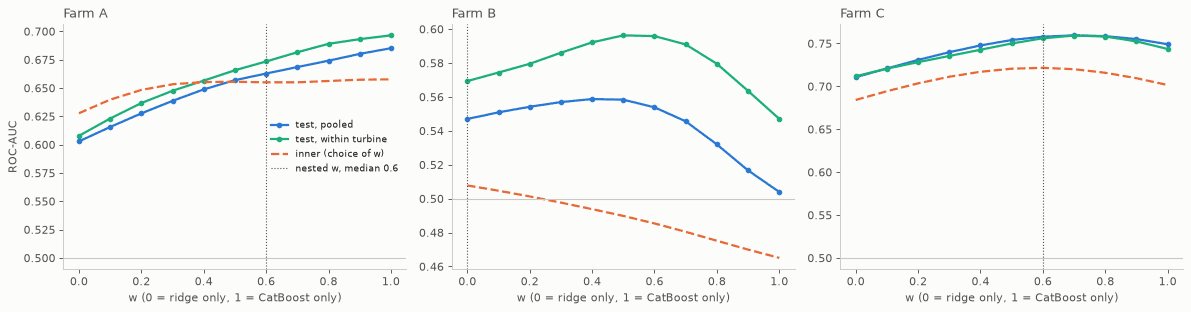

In [15]:
def within_auc(F_, y, s):
    tu = F_["turbine"].to_numpy()
    vals = []
    for t in np.unique(tu):
        m = (tu == t) & np.isfinite(y) & np.isfinite(s)
        if 0 < y[m].sum() < m.sum():
            vals.append((roc_auc_score(y[m], s[m]), y[m].sum()))
    return np.average([a for a, _ in vals], weights=[w for _, w in vals]) if vals else np.nan


wc = []
for f in FARMS:
    F_, R_ = FEAT[f], BL[f"{f}|full|y7"]
    y = F_["y7"].to_numpy(float)
    inner = R_["curve_inner"].groupby("w")["inner_auc"].mean()
    for i, w in enumerate(W_GRID):
        s = R_["blend_by_w"][i]
        wc.append({"farm": f, "w": w, "test ROC-AUC pooled": auc(y, s), "test ROC-AUC within turbine": within_auc(F_, y, s),
                   "inner ROC-AUC (mean over folds)": inner.loc[w]})
WC = pd.DataFrame(wc)
WC.to_csv(OUT2 / "results_weight_curve.csv", index=False)
display(WC.pivot_table(index="w", columns="farm", values=["test ROC-AUC pooled", "test ROC-AUC within turbine",
                                                         "inner ROC-AUC (mean over folds)"]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, f in zip(axes, FARMS):
    h = WC[WC["farm"] == f]
    ax.plot(h["w"], h["test ROC-AUC pooled"], color=BLUE, lw=2, marker="o", ms=4, label="test, pooled")
    ax.plot(h["w"], h["test ROC-AUC within turbine"], color=AQUA, lw=2, marker="o", ms=4, label="test, within turbine")
    ax.plot(h["w"], h["inner ROC-AUC (mean over folds)"], color=ORANGE, lw=2, ls="--", label="inner (choice of w)")
    ws = INFO.loc[INFO["farm"] == f, "w_star"]
    ax.axvline(ws.median(), color=INK2, lw=1, ls=":", label=f"nested w, median {ws.median():g}")
    ax.axhline(0.5, color=MUTED, lw=1)
    ax.set_title(f"Farm {f}", loc="left", color=INK2)
    ax.set_xlabel("w (0 = ridge only, 1 = CatBoost only)")
axes[0].set_ylabel("ROC-AUC")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT2 / "weight_curve.png", dpi=130, bbox_inches="tight")
show(fig)

**What the ridge model uses.** Mean standardised coefficient over the outer folds and seeds (features are standardised, so
the sizes are comparable inside a farm), top 10 by absolute value, with the share of folds where the sign agrees with the
mean.

In [16]:
for f in FARMS:
    co = BL[f"{f}|full|y7"]["coef"]
    g = co.groupby("feature")["coef"]
    T = pd.DataFrame({"mean coef": g.mean(), "sign agreement": g.apply(lambda s: np.mean(np.sign(s) == np.sign(s.mean())))})
    T = T.reindex(T["mean coef"].abs().sort_values(ascending=False).index).head(10)
    T["description"] = [describe(f, c) if "__" in c else c for c in T.index]
    print(f"=== farm {f}")
    display(T.round(4))

=== farm A


                              mean coef  sign agreement                                                  description
feature                                                                                                             
power_30_avg__m_chg              1.1711          1.0000                                      Grid power (avg), m_chg
power_29_std__m_chg              0.8558          0.9333                      Possible grid active power (std), m_chg
grp_speed_q_r14                  0.8223          1.0000                                              grp_speed_q_r14
sensor_6_avg__m_r7               0.7714          1.0000                Temperature in the hub controller (avg), m_r7
sensor_7_avg__m_chg              0.6948          0.9333       Temperature in the top nacelle controller (avg), m_chg
sensor_13_avg__m_chg            -0.6803          1.0000  Temperature in generator bearing 2 (Drive End) (avg), m_chg
reactive_power_27_std__m_chg    -0.6662          1.0000         

=== farm B


                      mean coef  sign agreement                                      description
feature                                                                                         
sensor_47_std__m_chg     1.5410             1.0        Transformer cell temperature (std), m_chg
sensor_47_avg__m_chg     1.4295             1.0        Transformer cell temperature (avg), m_chg
sensor_16_avg__m_chg    -1.1225             1.0                      RMS current L1 (avg), m_chg
grp_other_max_r14        0.8834             1.0                                grp_other_max_r14
ctx_amb                  0.8324             1.0                                          ctx_amb
sensor_22_avg__m_chg     0.7845             1.0                     Hub temperature (avg), m_chg
sensor_23_std__m_r7      0.7593             1.0                       Grid frequency (std), m_r7
grp_speed_q_chg         -0.7507             1.0                                  grp_speed_q_chg
sensor_22_std__m_chg     0.744

=== farm C


                       mean coef  sign agreement                                   description
feature                                                                                       
sensor_89_std__m_chg     -0.1279          1.0000    Motor current gear oil pump C (std), m_chg
sensor_89_avg__m_chg      0.1014          1.0000    Motor current gear oil pump C (avg), m_chg
sensor_213_std__m_r7      0.0979          1.0000                24VDC power pack 2 (std), m_r7
sensor_47_std__m_r7      -0.0948          1.0000           Mains frequency OS-side (std), m_r7
sensor_225_avg__m_r7      0.0921          1.0000           Water conductivity QIT1 (avg), m_r7
sensor_9_std__m_chg       0.0877          1.0000                 Battery charge 1 (std), m_chg
sensor_225_avg__m         0.0870          1.0000              Water conductivity QIT1 (avg), m
sensor_143_std__m_r7      0.0780          1.0000        Rotational speed aerator B (std), m_r7
sensor_218_std__m_chg     0.0780          1.0000  

## 11. Without ambient and temperatures (baseline rule 4)

Same engine on the `no_ambient_no_temp` features (no ambient context feature, no feature built from a temperature column,
no temperature group). The deviation residuals still use ambient as a covariate, as in the baseline.

In [17]:
abl = []
for f in FARMS:
    res = get_blend(f"{f}|no_ambient_no_temp|y7", FEAT[f], SETS[f]["no_ambient_no_temp"], "y7", "per_farm")
    for label, key in VARIANTS:
        r = evaluate(FEAT[f], res[key], "y7", EVENTS[f], n_boot=200)
        r["matched"] = matched_eval(FEAT[f], r["E"], ALL_META, f)
        EVAL[(f, label, "no_temp")] = r
        abl.append({"farm": f, "model": label, "ROC-AUC [95% CI]": ci(r, "roc_auc"),
                    "within turbine": round(r["point"]["within_turbine_auc"], 3),
                    "event recall [95% CI]": ci(r, "recall", "{:.2f}"),
                    "false alarms / turbine-month": round(r["point"]["fa_per_turbine_month"], 2),
                    "matched dataset AUC": round(r["matched"]["dataset AUC (max score)"], 3),
                    "full features ROC-AUC": round(EVAL[(f, label)]["point"]["roc_auc"], 3)})
ABL = pd.DataFrame(abl).set_index(["farm", "model"])
display(ABL)
ABL.to_csv(OUT2 / "results_ablation.csv")

  ran A|no_ambient_no_temp|y7 in 18 s


  ran B|no_ambient_no_temp|y7 in 31 s


  ran C|no_ambient_no_temp|y7 in 216 s


                               ROC-AUC [95% CI]  within turbine event recall [95% CI]  false alarms / turbine-month  matched dataset AUC  full features ROC-AUC
farm model                                                                                                                                                     
A    CatBoost per farm     0.688 [0.634, 0.786]           0.728     0.73 [0.61, 0.90]                          0.93                0.636                  0.658
     ridge logistic        0.486 [0.425, 0.603]           0.534     0.64 [0.45, 0.89]                          1.19                0.430                  0.569
     blend 50/50           0.567 [0.523, 0.703]           0.604     0.64 [0.45, 0.89]                          1.08                0.562                  0.635
     blend, nested weight  0.669 [0.632, 0.741]           0.704     0.64 [0.45, 0.89]                          1.01                0.562                  0.640
B    CatBoost per farm     0.384 [0.320,

## 12. Verdict against the baseline rules (baseline section 8)

For each new model and farm: (1) pooled ROC-AUC, within-turbine ROC-AUC and event recall all above CatBoost per farm, with
false alarms at most 1 per turbine-month on the test turbines; (2) beats season only (paired interval above zero);
(3) same-position dataset AUC above CatBoost's; (4) without ambient and temperatures, still above CatBoost's full-feature
pooled ROC-AUC.

In [18]:
ver = []
for f in FARMS:
    b = EVAL[(f, "CatBoost per farm")]
    for label, key in VARIANTS[1:]:
        r = EVAL[(f, label)]
        r1 = (r["point"]["roc_auc"] > b["point"]["roc_auc"] and r["point"]["within_turbine_auc"] > b["point"]["within_turbine_auc"]
              and r["point"]["recall"] > b["point"]["recall"] and r["point"]["fa_per_turbine_month"] <= FA_BUDGET)
        r2 = paired(f, label, "season only", "roc_auc")[1] == "yes"
        r3 = r["matched"]["dataset AUC (max score)"] > b["matched"]["dataset AUC (max score)"]
        r4 = EVAL[(f, label, "no_temp")]["point"]["roc_auc"] > b["point"]["roc_auc"]
        ver.append({"farm": f, "model": label, "1 metrics above CatBoost": r1, "2 beats season": r2,
                    "3 same position above CatBoost": r3, "4 holds without temperatures": r4,
                    "better than baseline": all([r1, r2, r3, r4]),
                    "significantly above CatBoost (pooled)": paired(f, label, "CatBoost per farm", "roc_auc")[1]})
VER = pd.DataFrame(ver).set_index(["farm", "model"])
display(VER)
VER.to_csv(OUT2 / "results_verdict.csv")
print(f"total run time {time.time() - T0:.0f} s")

                           1 metrics above CatBoost  2 beats season  3 same position above CatBoost  4 holds without temperatures  better than baseline significantly above CatBoost (pooled)
farm model                                                                                                                                                                                   
A    ridge logistic                           False           False                           False                         False                 False                             not shown
     blend 50/50                              False           False                           False                         False                 False                             not shown
     blend, nested weight                     False           False                           False                          True                 False                             not shown
B    ridge logistic                           Fals

total run time 421 s
